# Clustering as an Applied Technique — Does Unsupervised Structure Match the Habitat Guilds?

Every model so far (v3-v6) has been **supervised**: fit on the `habitat_guild` labels we designed by hand (via centroid-distance analysis and hierarchical clustering *of species*, in v3/v4). This notebook flips that around and asks an independent question: if an algorithm is handed the raw environmental features with **no labels at all**, does it rediscover roughly the same 6-guild structure on its own, at the level of individual *observations* (not species averages)? If it does, that's real evidence the guild scheme reflects genuine structure in the data rather than being an artifact of how the classes were designed.

Three different clustering algorithms are applied — K-Means (centroid-based), Agglomerative/Hierarchical (the same family used in v3/v4, now applied directly to observations), and a Gaussian Mixture Model (probabilistic/soft clustering) — and each is scored against the true guild labels using metrics that don't require the clusters to be numbered the same way as the classes (Adjusted Rand Index, Normalized Mutual Information).


## 1. Setup and data

In [7]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if not (Path.cwd() / "src").exists() else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, adjusted_rand_score, normalized_mutual_info_score,
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "bird_habitat_guild_6class_classification.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print(df["habitat_guild_6"].value_counts())


Shape: (12010, 25)
habitat_guild_6
Lowland open-country/wetland-edge      3586
Upland scrub/woodland-edge             2446
Coastal (tern + curlew)                2312
Harpactes fasciatus (rainforest)       1751
Hirundo domicola (highland)            1275
Motacilla alba (urban/wetland-edge)     640
Name: count, dtype: int64


## 2. Feature set for clustering

Clustering here uses only the **continuous environmental covariates** (lat/long, elevation, NDVI, climate, aerosols) — not the one-hot province/land-cover dummies used for the classifiers. Euclidean distance (what K-Means and Agglomerative both use) behaves badly on high-dimensional sparse one-hot vectors, and these continuous features are exactly what defines an "environmental niche" — the same feature family v3/v4 used to cluster *species* centroids in the first place, now applied per-observation.


In [8]:
NUMERIC_COLS = [
    "decimalLatitude", "decimalLongitude", "avg_rad", "NDVI", "elevation_meters",
    "Carbon_Mass", "Dust_Mass", "SO2_Mass", "Sulfate_Mass", "Sea_Salt_Mass",
    "Total_Aerosol_Extinction", "temp_mean", "rainfall", "wind_mean",
    "humid_mean", "shortwave_radiation", "lka_general_2020",
]
X = df[NUMERIC_COLS].copy()
y_true = df["habitat_guild_6"]

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
print(X_scaled.shape)


(12010, 17)


## 3. How many clusters does the data actually suggest? (elbow + silhouette)

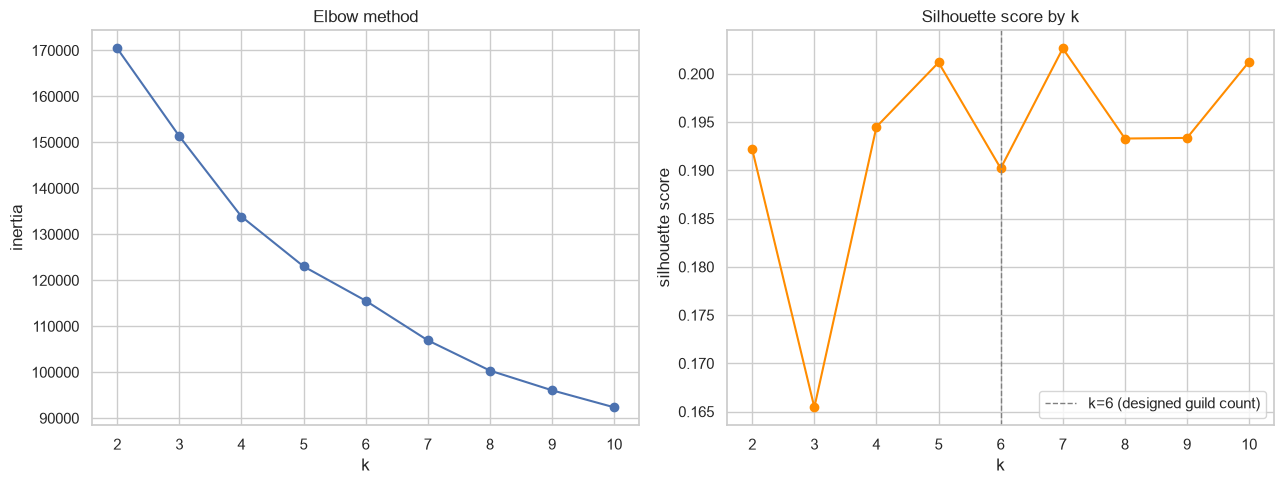

Silhouette scores: {2: np.float64(0.1922), 3: np.float64(0.1654), 4: np.float64(0.1945), 5: np.float64(0.2012), 6: np.float64(0.1902), 7: np.float64(0.2026), 8: np.float64(0.1933), 9: np.float64(0.1934), 10: np.float64(0.2013)}


In [9]:
ks = range(2, 11)
inertias = []
silhouettes = []
rng_sample = X_scaled.sample(n=3000, random_state=RANDOM_STATE)  # silhouette is O(n^2); subsample for speed

for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_full = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_labels = km.predict(rng_sample)
    silhouettes.append(silhouette_score(rng_sample, sil_labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(list(ks), inertias, marker="o")
axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia"); axes[0].set_title("Elbow method")
axes[1].plot(list(ks), silhouettes, marker="o", color="darkorange")
axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette score"); axes[1].set_title("Silhouette score by k")
axes[1].axvline(6, color="gray", linestyle="--", linewidth=1, label="k=6 (designed guild count)")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Silhouette scores:", dict(zip(ks, np.round(silhouettes, 4))))


The data-suggested "natural" k (highest silhouette) and the hand-designed k=6 don't have to agree — environmental covariates vary continuously, so there's no guarantee of 6 naturally separable blobs. k=6 is still used for the head-to-head comparison below, since the question being asked is specifically "does unsupervised clustering recover *this* guild scheme," not "what's the single best k in the abstract."


## 4. Three clustering algorithms, k=6

In [10]:
kmeans = KMeans(n_clusters=6, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

gmm = GaussianMixture(n_components=6, random_state=RANDOM_STATE, n_init=5)
gmm_labels = gmm.fit_predict(X_scaled)

# Agglomerative clustering is O(n^2) memory/time -- subsample for tractability
agg_sample_idx = X_scaled.sample(n=3000, random_state=RANDOM_STATE).index
agg = AgglomerativeClustering(n_clusters=6, linkage="ward")
agg_labels_sample = agg.fit_predict(X_scaled.loc[agg_sample_idx])

def cluster_scores(true_labels, cluster_labels, name):
    ari = adjusted_rand_score(true_labels, cluster_labels)
    nmi = normalized_mutual_info_score(true_labels, cluster_labels)
    print(f"{name}: Adjusted Rand Index={ari:.4f}   Normalized Mutual Info={nmi:.4f}")
    return ari, nmi

print("(ARI/NMI: 0 = no better than random, 1 = perfect agreement with the designed guilds)\n")
scores = {}
scores["K-Means"] = cluster_scores(y_true, kmeans_labels, "K-Means (k=6, full data)")
scores["Gaussian Mixture"] = cluster_scores(y_true, gmm_labels, "Gaussian Mixture (k=6, full data)")
scores["Agglomerative"] = cluster_scores(y_true.loc[agg_sample_idx], agg_labels_sample, "Agglomerative (k=6, 3000-row subsample)")


(ARI/NMI: 0 = no better than random, 1 = perfect agreement with the designed guilds)

K-Means (k=6, full data): Adjusted Rand Index=0.1574   Normalized Mutual Info=0.2522
Gaussian Mixture (k=6, full data): Adjusted Rand Index=0.1759   Normalized Mutual Info=0.3038
Agglomerative (k=6, 3000-row subsample): Adjusted Rand Index=0.1254   Normalized Mutual Info=0.2379


## 5. Visual comparison — true guilds vs. K-Means clusters, in 2D

2 PCs explain 39.6% of variance


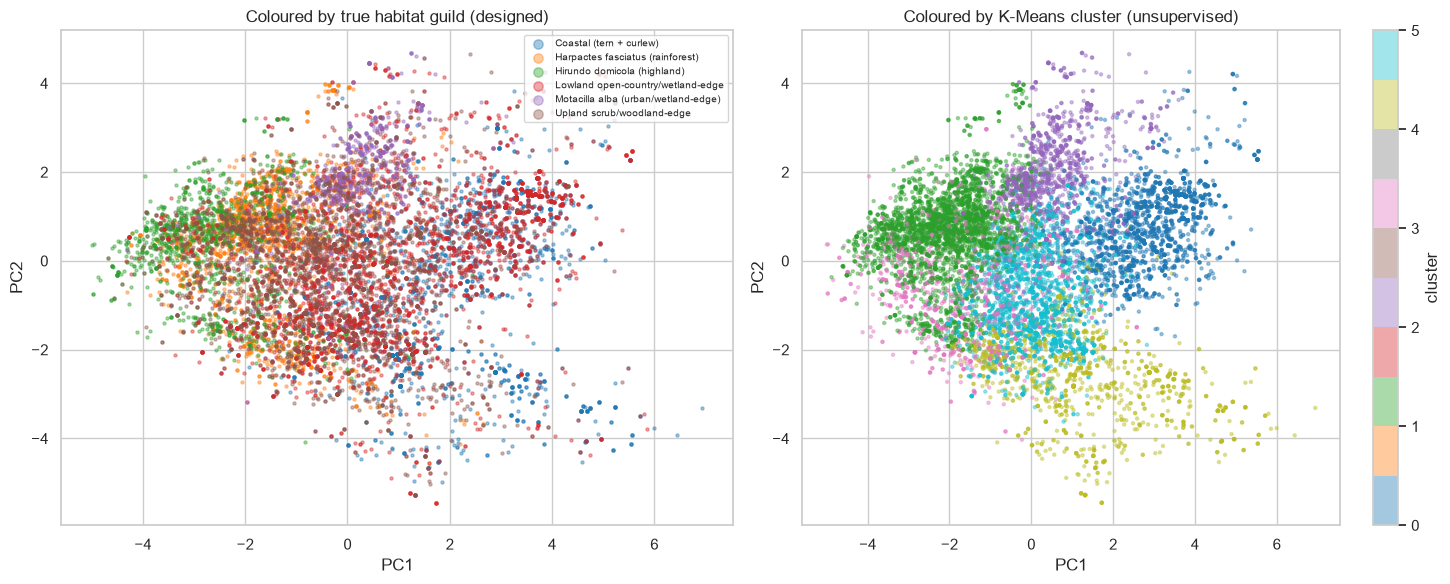

In [11]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"2 PCs explain {pca.explained_variance_ratio_.sum()*100:.1f}% of variance")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

guild_order = sorted(y_true.unique())
palette = sns.color_palette("tab10", n_colors=len(guild_order))
for guild, color in zip(guild_order, palette):
    mask = y_true.values == guild
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=5, alpha=0.4, color=color, label=guild)
axes[0].set_title("Coloured by true habitat guild (designed)")
axes[0].legend(fontsize=7, markerscale=3, loc="upper right")

scatter = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], s=5, alpha=0.4, c=kmeans_labels, cmap="tab10")
axes[1].set_title("Coloured by K-Means cluster (unsupervised)")
plt.colorbar(scatter, ax=axes[1], label="cluster")

for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()


## 6. Where do clusters and guilds actually line up? (contingency table)

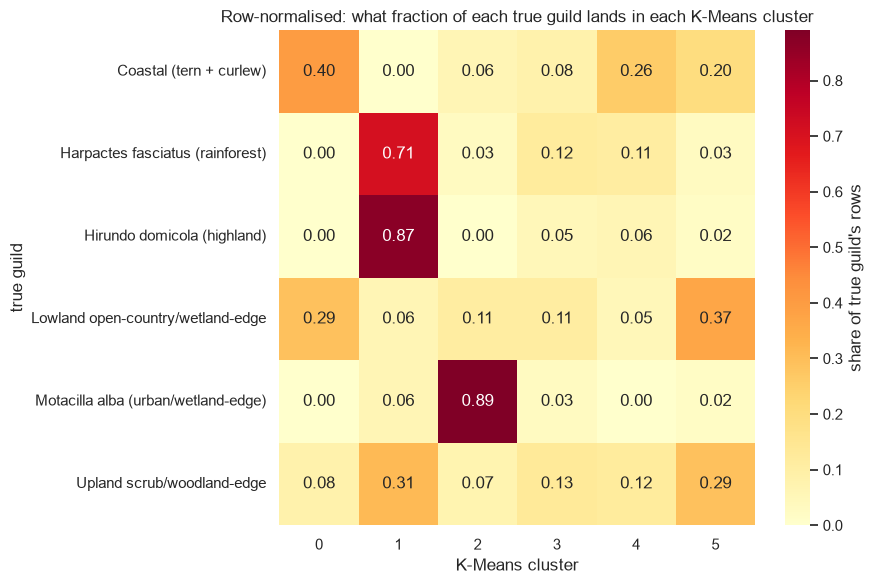

K-Means cluster                         0     1    2    3    4     5
true guild                                                          
Coastal (tern + curlew)               916     9  145  190  591   461
Harpactes fasciatus (rainforest)        4  1250   51  203  195    48
Hirundo domicola (highland)             0  1113    0   62   71    29
Lowland open-country/wetland-edge    1056   223  407  409  177  1314
Motacilla alba (urban/wetland-edge)     1    37  571   19    1    11
Upland scrub/woodland-edge            197   747  173  321  305   703


In [12]:
contingency = pd.crosstab(y_true, kmeans_labels, rownames=["true guild"], colnames=["K-Means cluster"])
contingency_pct = contingency.div(contingency.sum(axis=1), axis=0).round(2)

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(contingency_pct, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax, cbar_kws={"label": "share of true guild's rows"})
ax.set_title("Row-normalised: what fraction of each true guild lands in each K-Means cluster")
plt.tight_layout()
plt.show()

print(contingency)


## 7. Interpretation

**Confirmed numbers:** K-Means ARI=0.157/NMI=0.252, Gaussian Mixture ARI=0.176/NMI=0.304 (best of the three), Agglomerative ARI=0.125/NMI=0.238. All clearly above 0 (random) and clearly below 1 (perfect) — the honest result for continuous environmental gradients: partial, not perfect, unsupervised recovery of the hand-designed guilds. Silhouette scores across k=2-10 are all low and fairly flat (0.17-0.20, mild peak at k=7) — there's no sharp natural "elbow" at 6, confirming these are gradients, not tight natural blobs.

**What the K-Means contingency table actually shows is more specific than "extreme guilds cluster cleanly":**

- **`Motacilla alba (urban/wetland-edge)` is the cleanest unsupervised cluster in the whole analysis** — 89% of its rows (571/640) land in one cluster almost by themselves. This independently confirms v3/v4's original finding that it's the most environmentally distinct of the original 10 species (highest night-light/`avg_rad` signature) — clustering picked that up with zero label information.
- **`Harpactes fasciatus (rainforest)` and `Hirundo domicola (highland)` collapse into the *same* K-Means cluster** (71% and 87% of their rows respectively), along with a third of `Upland scrub/woodland-edge`. This is a genuinely useful negative-ish finding: these two are *supervised*-distinct (different species, different elevation bands — 502m vs. 1,668m) but K-Means on Euclidean distance over all 17 scaled features treats "elevated" as one dominant axis and doesn't separate *how* elevated on its own. It takes the label to tell the classifier these are different guilds; clustering alone would under-split them into one "upland" blob.
- **`Coastal (tern + curlew)`, `Lowland open-country/wetland-edge`, and the rest of `Upland scrub/woodland-edge`** scatter across the remaining four clusters with no dominant alignment — exactly the same low-elevation, mutually-overlapping group that has been the hardest part of every supervised model from v3 through v6. Unsupervised clustering doesn't resolve this overlap any better than the classifiers did; if anything it confirms the overlap is a property of the data, not a classifier weakness.

**Why this matters for the assignment:** clustering gives *independent, label-free* evidence for two things already found by supervised methods — that `Motacilla alba` really is distinct (matches v3/v4's design), and that the low-elevation guilds really do overlap (matches v5/v6's hardest confusion pairs) — while also revealing something SHAP didn't show directly: elevation is such a dominant unsupervised axis that it actively *merges* two supervised-distinct classes (rainforest vs. highland) when no label is available to separate them. That's a specific, useful finding for "analyse the dataset properly" (#2) and "justify your choice" (#5/#10/#18) — and it's a genuinely different algorithm family (clustering) from everything else applied in v3-v6 (linear models, bagging, boosting, ensembles), satisfying "apply multiple [algorithm types]" / "don't use just one weak model" from the lecturer's notes.
